<h1 align="center"> Lingüística Computacional - MIARFID</h1>
<h1 align="center"> Trabajo final - Análisis exploratorio de datos</h1>

**Estudiantes:** Carlos Broch Cubedo · Ferran Artero Merino

# 0. Configuración

In [3]:
!pip -q install iterative-stratification

In [4]:
import os, re, ast, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn import metrics
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold, MultilabelStratifiedShuffleSplit
from google.colab import drive

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 0

drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/LC_TrabajoFinal"
FIG_DIR = os.path.join(DATA_DIR, "outputs", "eda")
os.makedirs(FIG_DIR, exist_ok=True)
TRAIN_FILE = os.path.join(DATA_DIR, "dataset_train.csv")
TEST_FILE = os.path.join(DATA_DIR, "dataset_test.csv")

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()

Mounted at /content/drive


# 1. Duplicados
Se agrupan las filas por título y resumen normalizados y se comprueba si las copias tienen etiquetas distintas.

In [5]:
raw = pd.read_csv(TRAIN_FILE)
raw["labels"] = raw["terms"].map(lambda s: list(ast.literal_eval(s)))
CLASSES = sorted({l for ls in raw["labels"] for l in ls})
print("Dimensiones:", raw.shape, "| nulos:", int(raw.isna().sum().sum()), "| clases:", len(CLASSES))

Dimensiones: (43555, 4) | nulos: 0 | clases: 28


In [6]:
def norm(s):
    s = str(s).lower()
    s = re.sub(r"\$[^$]*\$", " ", s)
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

raw["title_n"], raw["summary_n"] = raw["titles"].map(norm), raw["summaries"].map(norm)
raw["labelset"] = raw["labels"].map(lambda l: tuple(sorted(set(l))))

rep = raw.groupby(["title_n", "summary_n"]).size()
n_dup = len(raw) - len(rep)
print(f"Filas: {len(raw)} | artículos únicos: {len(rep)} | copias: {n_dup} ({100 * n_dup / len(raw):.0f} %)")
print(f"Artículos repetidos: {(rep > 1).sum()} | veces que aparecen:", rep[rep > 1].value_counts().sort_index().to_dict())

g = raw.groupby(["title_n", "summary_n"])["labelset"].agg(set)
conflict = g[g.map(len) > 1]
print(f"Repetidos con etiquetas distintas: {len(conflict)}")
for sets in conflict:
    print("  ", [list(s) for s in sets])

Filas: 43555 | artículos únicos: 32577 | copias: 10978 (25 %)
Artículos repetidos: 8900 | veces que aparecen: {2: 7130, 3: 1505, 4: 229, 5: 30, 6: 5, 7: 1}
Repetidos con etiquetas distintas: 6
   [['cs.AI', 'cs.LG'], ['cs.LG']]
   [['cs.CV'], ['cs.CV', 'cs.LG']]
   [['cs.LG', 'stat.ML'], ['cs.LG']]
   [['cs.LG', 'stat.ML'], ['cs.CL', 'cs.LG', 'stat.ML']]
   [['cs.CV', 'stat.ML'], ['cs.CV']]
   [['cs.AI', 'cs.CV', 'cs.LG'], ['cs.CV']]


In [7]:
# Un artículo por fila; las etiquetas de las copias se unen
data = (raw.groupby(["title_n", "summary_n"], sort=False)
           .agg(titles=("titles", "first"), summaries=("summaries", "first"),
                labels=("labels", lambda ls: sorted({l for x in ls for l in x})))
           .reset_index())
data["text"] = data["titles"].map(lambda s: re.sub(r"\s+", " ", s).strip()) + ". " + \
               data["summaries"].map(lambda s: re.sub(r"\s+", " ", s).strip())
Y = MultiLabelBinarizer(classes=CLASSES).fit_transform(data["labels"])
N, L = Y.shape
print(f"Artículos únicos: {N} | clases: {L}")

Artículos únicos: 32577 | clases: 28


# 2. Desequilibrio de clases
Frecuencia de cada categoría sobre los artículos únicos.

In [8]:
freq = pd.Series(Y.sum(0), index=CLASSES).sort_values(ascending=False)
lab = pd.DataFrame({"artículos": freq, "% artículos": (100 * freq / N).round(2)})
lab["grupo"] = pd.cut(lab["artículos"], [0, 100, 1000, np.inf], labels=["rara (<100)", "media (100-1000)", "frecuente (>1000)"])
display(lab)
print(f"Ratio más frecuente / más rara: {freq.max() / freq.min():.0f}")
print("Clases por grupo:", lab["grupo"].value_counts().to_dict())

,artículos,% artículos,grupo
cs.CV,19787,60.74,frecuente (>1000)
cs.LG,17166,52.69,frecuente (>1000)
stat.ML,9567,29.37,frecuente (>1000)
cs.AI,4498,13.81,frecuente (>1000)
eess.IV,1261,3.87,frecuente (>1000)
cs.RO,1055,3.24,frecuente (>1000)
cs.CL,704,2.16,media (100-1000)
cs.NE,509,1.56,media (100-1000)
cs.CR,274,0.84,media (100-1000)
cs.SI,263,0.81,media (100-1000)


Ratio más frecuente / más rara: 989
Clases por grupo: {'rara (<100)': 12, 'media (100-1000)': 10, 'frecuente (>1000)': 6}


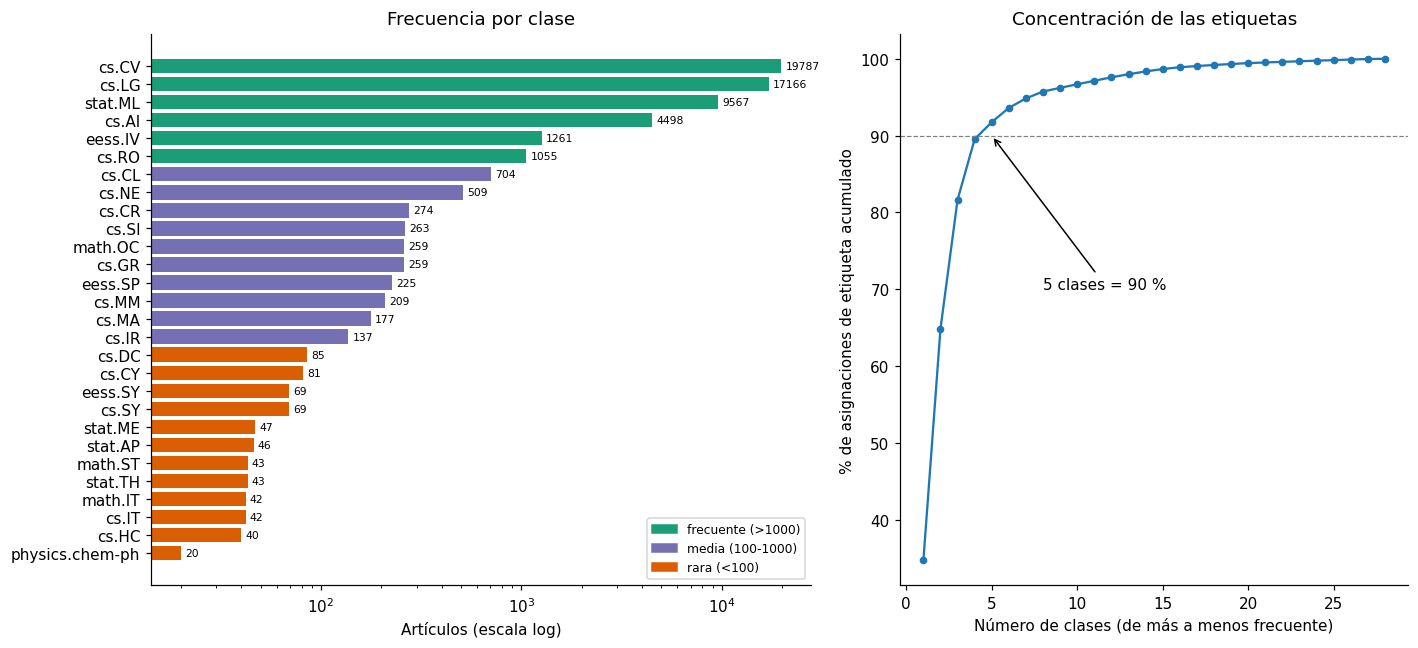

In [9]:
colors = lab["grupo"].map({"rara (<100)": "#d95f02", "media (100-1000)": "#7570b3", "frecuente (>1000)": "#1b9e77"})
fig, ax = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].barh(lab.index[::-1], lab["artículos"][::-1], color=colors[::-1])
ax[0].set_xscale("log"); ax[0].set_xlabel("Artículos (escala log)"); ax[0].set_title("Frecuencia por clase")
for i, v in enumerate(lab["artículos"][::-1]):
    ax[0].text(v * 1.05, i, str(v), va="center", fontsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#1b9e77", "#7570b3", "#d95f02"]]
ax[0].legend(handles, ["frecuente (>1000)", "media (100-1000)", "rara (<100)"], loc="lower right", fontsize=8)

cum = freq.cumsum() / freq.sum() * 100
k90 = int((cum < 90).sum() + 1)
ax[1].plot(range(1, L + 1), cum.values, "o-", ms=4)
ax[1].axhline(90, ls="--", c="gray", lw=.8)
ax[1].set_xlabel("Número de clases (de más a menos frecuente)"); ax[1].set_ylabel("% de asignaciones de etiqueta acumulado")
ax[1].set_title("Concentración de las etiquetas")
ax[1].annotate(f"{k90} clases = 90 %", (k90, 90), xytext=(k90 + 3, 70), arrowprops=dict(arrowstyle="->"))
savefig("02_frecuencia_clases")

In [10]:
# Positivos de las clases más raras en cada partición estratificada
mskf = MultilabelStratifiedKFold(5, shuffle=True, random_state=SEED)
fold_tab = pd.DataFrame({f"fold {k}": Y[te].sum(0) for k, (_, te) in enumerate(mskf.split(np.zeros(N), Y))}, index=CLASSES)
display(fold_tab.loc[freq.index[::-1][:10]].T)

,physics.chem-ph,cs.HC,cs.IT,math.IT,stat.TH,math.ST,stat.AP,stat.ME,cs.SY,eess.SY
fold 0,4,8,9,9,8,8,9,10,13,13
fold 1,4,8,9,9,8,8,9,9,14,14
fold 2,4,8,8,8,9,9,10,9,14,14
fold 3,4,8,8,8,9,9,9,9,14,14
fold 4,4,8,8,8,9,9,9,10,14,14


# 3. Estructura de las etiquetas
Número de etiquetas por artículo, combinaciones, categorías raíz y relaciones entre etiquetas (alias e inclusiones).

In [11]:
card = Y.sum(1)
print(f"Etiquetas por artículo: media {card.mean():.2f}, rango {card.min()}-{card.max()}, con una sola {100 * (card == 1).mean():.0f} %")
print("Combinaciones distintas:", data["labels"].map(tuple).nunique())
print("Clases que aparecen solas:", [c for j, c in enumerate(CLASSES) if ((Y[:, j] == 1) & (card == 1)).any()])

ROOTS = ["cs.CV", "cs.LG", "stat.ML"]
is_root = np.isin(CLASSES, ROOTS)
print(f"Con al menos una raíz: {100 * (Y[:, is_root].sum(1) > 0).mean():.1f} % | "
      f"solo raíces: {100 * (Y[:, ~is_root].sum(1) == 0).mean():.1f} %")

Etiquetas por artículo: media 1.75, rango 1-4, con una sola 46 %
Combinaciones distintas: 71
Clases que aparecen solas: ['cs.CV', 'cs.LG', 'stat.ML']
Con al menos una raíz: 100.0 % | solo raíces: 70.7 %


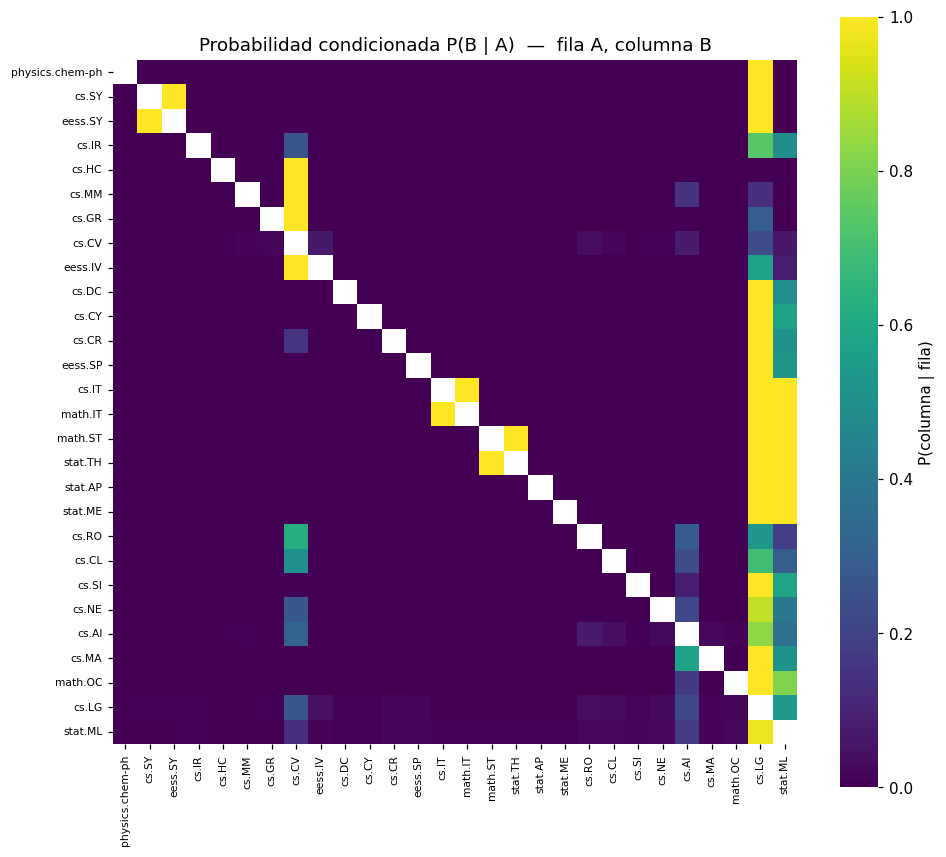

In [12]:
C = (Y.T @ Y).astype(float)
n = np.diag(C)
P_cond = pd.DataFrame(C / n[:, None], index=CLASSES, columns=CLASSES)   # fila A, columna B: P(B | A)

# Orden de las clases: clustering jerárquico sobre NPMI
with np.errstate(divide="ignore", invalid="ignore"):
    P_ab = C / N
    npmi = np.log(P_ab / np.outer(n / N, n / N)) / -np.log(P_ab)
npmi[C == 0] = -1
np.fill_diagonal(npmi, 1)
D = 1 - npmi; np.fill_diagonal(D, 0)
order = [CLASSES[i] for i in leaves_list(linkage(squareform((D + D.T) / 2, checks=False), method="average"))]

plt.figure(figsize=(9, 8))
sns.heatmap(P_cond.loc[order, order], cmap="viridis", square=True, mask=np.eye(L, dtype=bool), vmin=0, vmax=1,
            cbar_kws={"label": "P(columna | fila)"})
plt.title("Probabilidad condicionada P(B | A)  —  fila A, columna B")
plt.tick_params(labelsize=7)
savefig("03_probabilidad_condicionada")

In [13]:
P = P_cond.values
alias = [(a, b) for i, a in enumerate(CLASSES) for j, b in enumerate(CLASSES) if i < j and P[i, j] == 1 and P[j, i] == 1]
print("Alias (siempre juntas):", alias)
print("Inclusiones (P(B | A) = 1):")
for j, b in enumerate(CLASSES):
    subs = [a for i, a in enumerate(CLASSES) if i != j and P[i, j] == 1 and P[j, i] < 1]
    if subs:
        print(f"  {b}  <-  {subs}")

Alias (siempre juntas): [('cs.IT', 'math.IT'), ('cs.SY', 'eess.SY'), ('math.ST', 'stat.TH')]
Inclusiones (P(B | A) = 1):
  cs.CV  <-  ['cs.GR', 'cs.HC', 'cs.MM', 'eess.IV']
  cs.LG  <-  ['cs.CR', 'cs.CY', 'cs.DC', 'cs.IT', 'cs.MA', 'cs.SI', 'cs.SY', 'eess.SP', 'eess.SY', 'math.IT', 'math.OC', 'math.ST', 'physics.chem-ph', 'stat.AP', 'stat.ME', 'stat.TH']
  stat.ML  <-  ['cs.IT', 'math.IT', 'math.ST', 'stat.AP', 'stat.ME', 'stat.TH']


# 4. Texto
Longitudes, ruido de formato y aporte del título y del resumen por separado.

In [14]:
data["title_words"] = data["titles"].str.split().str.len()
data["summary_words"] = data["summaries"].str.split().str.len()
display(data[["title_words", "summary_words"]].describe(percentiles=[.5, .95]).T.round(1))

noise = {"saltos de línea": r"\n", "LaTeX ($...$)": r"\$[^$]+\$", "URL": r"https?://|www\."}
display(pd.Series({k: 100 * data["summaries"].str.contains(p).mean() for k, p in noise.items()}).round(1).to_frame("% de resúmenes"))

has_latex = data["summaries"].str.contains(r"\$[^$]+\$")
latex_by_class = pd.Series({c: 100 * has_latex[Y[:, j] == 1].mean() for j, c in enumerate(CLASSES)})
display(latex_by_class.sort_values(ascending=False).round(1).to_frame("% con LaTeX").T)

,count,mean,std,min,50%,95%,max
title_words,32577.0,8.8,3.0,1.0,9.0,14.0,30.0
summary_words,32577.0,171.3,45.1,5.0,169.0,250.0,326.0


,% de resúmenes
saltos de línea,100.0
LaTeX ($...$),6.2
URL,9.7


,math.OC,cs.IT,math.IT,stat.TH,math.ST,cs.DC,stat.ME,cs.CY,stat.ML,cs.CR,...,cs.NE,cs.IR,eess.IV,stat.AP,cs.CV,cs.MA,cs.RO,cs.MM,cs.GR,cs.HC
% con LaTeX,34.4,28.6,28.6,27.9,27.9,12.9,12.8,11.1,9.8,8.4,...,4.5,4.4,4.4,4.3,4.1,4.0,3.6,2.9,2.7,2.5


In [15]:
# TF-IDF + SVM lineal con partición estratificada 80/20
tr, te = next(MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(np.zeros(N), Y))
res = {}
for name, txt in {"título": data["titles"], "resumen": data["summaries"], "título + resumen": data["text"]}.items():
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=200_000)
    clf = OneVsRestClassifier(LinearSVC(C=0.3, class_weight="balanced"), n_jobs=-1).fit(vec.fit_transform(txt.iloc[tr]), Y[tr])
    pred = clf.predict(vec.transform(txt.iloc[te]))
    res[name] = {"F1 macro": metrics.f1_score(Y[te], pred, average="macro", zero_division=0),
                 "F1 micro": metrics.f1_score(Y[te], pred, average="micro", zero_division=0)}
display(pd.DataFrame(res).T.round(4))

,F1 macro,F1 micro
título,0.2462,0.7117
resumen,0.2374,0.7771
título + resumen,0.2418,0.7794


# 5. Entrenamiento frente a test
El test contiene artículos más recientes. Se mide el desplazamiento con el vocabulario nuevo y una validación adversarial.

In [16]:
test = pd.read_csv(TEST_FILE)
test["text"] = (test["titles"].map(lambda s: re.sub(r"\s+", " ", str(s)).strip()) + ". " +
                test["summaries"].map(lambda s: re.sub(r"\s+", " ", str(s)).strip()))
test["summary_words"] = test["summaries"].astype(str).str.split().str.len()
print("Test:", test.shape, list(test.columns))

overlap = set(zip(test["titles"].map(norm), test["summaries"].map(norm))) & set(zip(data["title_n"], data["summary_n"]))
print("Artículos del test que están en entrenamiento:", len(overlap))
display(pd.DataFrame({"train": data["summary_words"].describe(), "test": test["summary_words"].describe()}).round(1).T)

Test: (4885, 5) ['titles', 'summaries', 'keywords', 'text', 'summary_words']
Artículos del test que están en entrenamiento: 0


,count,mean,std,min,25%,50%,75%,max
train,32577.0,171.3,45.1,5.0,140.0,169.0,200.0,326.0
test,4885.0,186.4,38.7,29.0,159.0,186.0,214.0,305.0


In [17]:
an = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b").build_analyzer()
tr_cnt = collections.Counter(w for t in data["text"].str.lower() for w in an(t))
te_cnt = collections.Counter(w for t in test["text"].str.lower() for w in an(t))
oov_tok = sum(c for w, c in te_cnt.items() if w not in tr_cnt) / sum(te_cnt.values())
oov_typ = np.mean([w not in tr_cnt for w in te_cnt])
print(f"Fuera del vocabulario de entrenamiento: {100 * oov_tok:.1f} % de los tokens, {100 * oov_typ:.1f} % de los tipos")
print("Términos más frecuentes del test que no aparecen en entrenamiento:")
print(", ".join(w for w, _ in sorted(((w, c) for w, c in te_cnt.items() if w not in tr_cnt), key=lambda x: -x[1])[:30]))

Fuera del vocabulario de entrenamiento: 5.5 % de los tokens, 48.3 % de los tipos
Términos más frecuentes del test que no aparecen en entrenamiento:
llms, llm, vlms, mllms, grpo, in-context, lora, agentic, kv, rlvr, chain-of-thought, mllm, icl, llm-based, vla, opd, dit, flow-matching, lvlms, tabpfn, llama-, tsfms, rope, vfms, few-step, vision-language-action, peft, dpo, rlhf, sheaf


AUC = 0.980


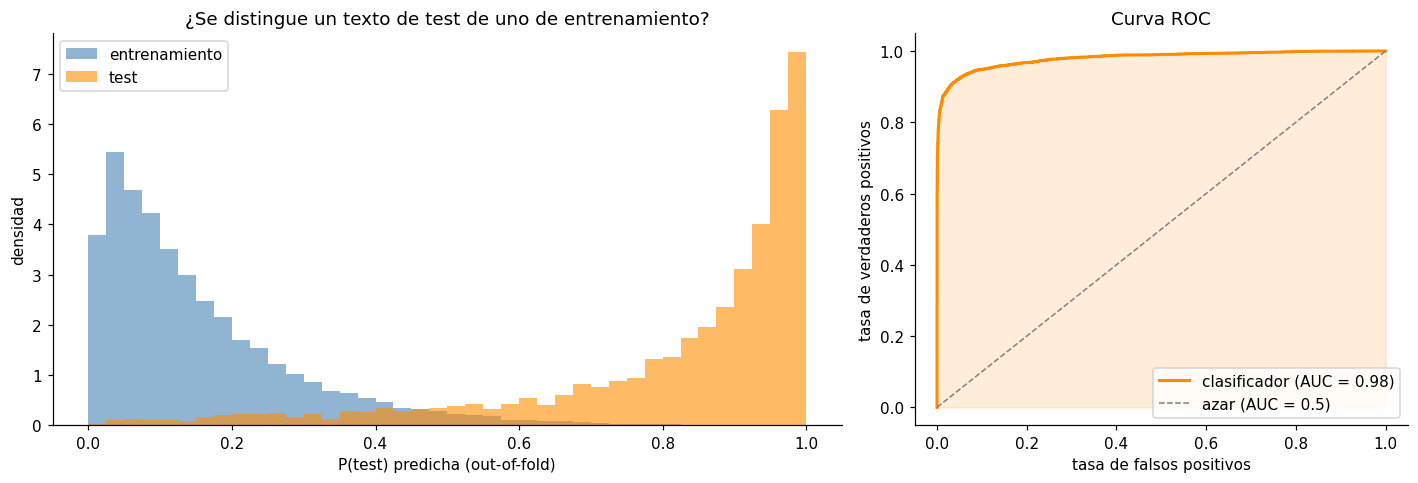

In [18]:
# Validación adversarial: regresión logística sobre TF-IDF que distingue train de test
m = min(len(test) * 3, N)
adv_txt = pd.concat([data["text"].sample(m, random_state=SEED), test["text"]]).tolist()
adv_y = np.r_[np.zeros(m), np.ones(len(test))]
adv_X = TfidfVectorizer(min_df=3, sublinear_tf=True, stop_words="english").fit_transform(adv_txt)
adv_p = cross_val_predict(LogisticRegression(max_iter=2000, C=1, class_weight="balanced"), adv_X, adv_y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
AUC = metrics.roc_auc_score(adv_y, adv_p)
fpr, tpr, _ = metrics.roc_curve(adv_y, adv_p)
print(f"AUC = {AUC:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
bins = np.linspace(0, 1, 41)
ax[0].hist(adv_p[adv_y == 0], bins=bins, density=True, alpha=.6, color="steelblue", label="entrenamiento")
ax[0].hist(adv_p[adv_y == 1], bins=bins, density=True, alpha=.6, color="darkorange", label="test")
ax[0].set_xlabel("P(test) predicha (out-of-fold)"); ax[0].set_ylabel("densidad"); ax[0].legend(loc="upper left")
ax[0].set_title("¿Se distingue un texto de test de uno de entrenamiento?")
ax[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"clasificador (AUC = {AUC:.2f})")
ax[1].fill_between(fpr, tpr, alpha=.15, color="darkorange")
ax[1].plot([0, 1], [0, 1], "--", c="gray", lw=1, label="azar (AUC = 0.5)")
ax[1].set_xlabel("tasa de falsos positivos"); ax[1].set_ylabel("tasa de verdaderos positivos")
ax[1].set_title("Curva ROC"); ax[1].legend(loc="lower right")
savefig("05_validacion_adversarial")

In [19]:
def parse_kw(s):
    try:
        v = ast.literal_eval(s)
        v = v if isinstance(v, (list, tuple)) else [v]
    except Exception:
        v = re.split(r"[;,]", str(s))
    return [str(x).strip(" '\"").lower() for x in v if str(x).strip(" '\"")]

test["kw"] = test["keywords"].fillna("[]").map(parse_kw)
kw_cnt = collections.Counter(k for ks in test["kw"] for k in ks)
print(f"Keywords por artículo: {test['kw'].map(len).mean():.2f} | distintas: {len(kw_cnt)}")
display(pd.Series(dict(kw_cnt.most_common())).to_frame("artículos").T)

Keywords por artículo: 1.28 | distintas: 29


,attention,adversarial training,reinforcement learning,representation learning,time series,image generation,transformers,object detection,point cloud,explainable,...,structured data,radiance field,optical flow,few-shot learning,generative adversarial networks,molecule,model compressions,decision tree,semi-supervised learning,unsupervised learning
artículos,607,556,539,419,406,396,379,350,292,248,...,70,70,68,57,56,54,47,47,42,35
